# Ames House Price Prediction
## Project notebook

We predict sale prices for 1,459 test houses using 1,460 labelled houses from
the Kaggle House Prices competition. This notebook follows the same five
milestones as our project report. We start with a small Ridge reference,
review the comparisons that guided our later choices, and build the final
submission under **V5**. Its recorded Kaggle log-RMSE is **0.11101**.

### Contents
- [Task, dataset and EDA](#task-and-dataset)
- [V1: finding a useful starting point](#v1-start)
- [V2: comparing and combining predictions](#v2-comparison)
- [V3: improving the inputs and comparing alternatives](#v3-inputs)
- [V4: putting each house in its neighbourhood](#v4-neighbourhood)
- [V5: refining the final predictions](#v5-final)
- [Submission results and final checks](#submission-results)

### Run
Open this notebook inside a clone of the repository, install
`requirements-v1.txt` in the selected Python kernel, and run all cells in order.
The notebook uses the repository files without downloading data.

We train the Ridge reference here. The middle milestones review saved OOF
predictions and experiment records; V5 combines saved component predictions
and applies the final sale-condition and comparable-sale rules.
Each later model branch retains the processing used in its original run.
The notebook does not retrain every component of the final combination.

The final file is `final_outputs/submission_final.csv`. The Ridge reference,
comparison tables and run record are saved separately in the same folder.

<a id="task-and-dataset"></a>
## Task and dataset
We have 79 predictors after excluding `Id` and `SalePrice`, covering area,
quality, age, neighbourhood, facilities and sale conditions. We keep `Id`
only to match output rows. Kaggle measures RMSE on log prices, so lower is better.

### Import libraries

In [1]:
from pathlib import Path
from time import perf_counter
from hashlib import sha256
from io import BytesIO, StringIO
import csv
import json
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from threadpoolctl import threadpool_limits

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_columns", 12)

### Read and check the data
We preserve the literal category `None` and treat blank cells and `NA` as
missing. We also check the saved inputs needed for the later comparisons.
The asset manifest links descriptive component names to the prediction archive.

In [2]:
current = Path.cwd()
root_candidates = list(dict.fromkeys([current, current / "Proj", *current.parents]))
REPO_ROOT = next((p for p in root_candidates
                  if (p / "Dataset/train.csv").is_file()
                  and (p / "final_versions/notebook_assets.json").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete repository, including final_versions/notebook_assets.json.")
DATA_DIR = REPO_ROOT / "Dataset"
OUTPUT_DIR = REPO_ROOT / "final_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
ASSET_MANIFEST = REPO_ROOT / "final_versions/notebook_assets.json"
assets = json.loads(ASSET_MANIFEST.read_text())
SOURCE_COMMIT = assets["source_commit"]
required_paths = []

def asset_path(section, name):
    specification = assets[section][name]
    path = REPO_ROOT / specification["path"]
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved input: {section}/{name}")
    if sha256(path.read_bytes()).hexdigest() != specification["sha256"]:
        raise ValueError(f"Saved input has changed: {section}/{name}")
    return path

for section in ["components", "checkpoints", "experiment_records"]:
    for name in assets[section]:
        required_paths.append(asset_path(section, name))

train = pd.read_csv(DATA_DIR / "train.csv", keep_default_na=False, na_values=["", "NA"])
test = pd.read_csv(DATA_DIR / "test.csv", keep_default_na=False, na_values=["", "NA"])
print("Train:", train.shape, "Test:", test.shape)
display(train.head())

Train: (1460, 81) Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,...,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,...,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,...,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,...,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,...,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,...,0,12,2008,WD,Normal,250000


In [3]:
train.info()
data_checks = pd.Series({
    "Training rows": len(train), "Test rows": len(test),
    "Duplicate training IDs": int(train["Id"].duplicated().sum()),
    "Duplicate test IDs": int(test["Id"].duplicated().sum()),
    "Missing target values": int(train["SalePrice"].isna().sum()),
    "Non-positive targets": int((train["SalePrice"] <= 0).sum()),
})
display(data_checks.to_frame("Value"))
assert train.shape == (1460, 81) and test.shape == (1459, 80)
assert train["Id"].is_unique and test["Id"].is_unique
assert set(train["Id"]).isdisjoint(test["Id"])
assert "SalePrice" not in test.columns
assert train["SalePrice"].notna().all() and train["SalePrice"].gt(0).all()
def frame_fingerprint(frame):
    return sha256(pd.util.hash_pandas_object(frame, index=True).values.tobytes()).hexdigest()
raw_fingerprints = {"train": frame_fingerprint(train), "test": frame_fingerprint(test)}

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,Value
Training rows,1460
Test rows,1459
Duplicate training IDs,0
Duplicate test IDs,0
Missing target values,0
Non-positive targets,0


### A brief look at the data
We first check the target distribution. The long upper tail makes the raw
prices uneven; taking natural logs gives us a less skewed target and matches
the competition's evaluation scale.

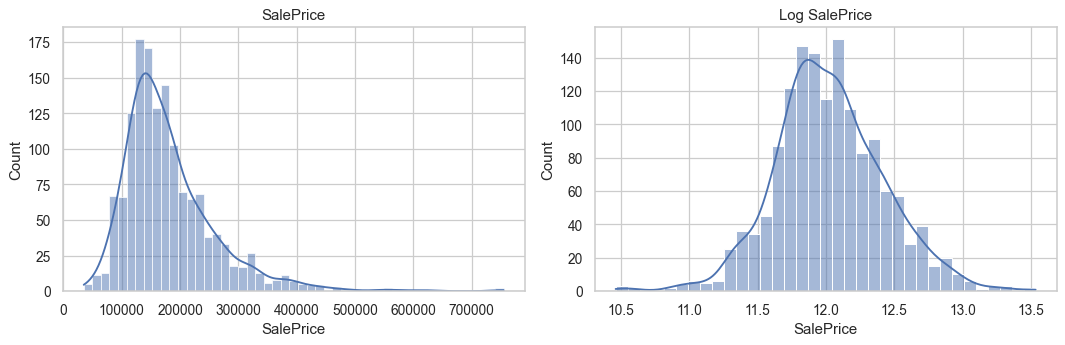

,Value
Minimum price,34900.000000
Median price,163000.000000
Maximum price,755000.000000
Raw-price skewness,1.882876
Log-price skewness,0.121335


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice")
sns.histplot(np.log(train["SalePrice"]), kde=True, ax=axes[1])
axes[1].set_title("Log SalePrice")
plt.tight_layout()
plt.show()

display(pd.Series({"Minimum price": train.SalePrice.min(), "Median price": train.SalePrice.median(), "Maximum price": train.SalePrice.max(), "Raw-price skewness": train.SalePrice.skew(), "Log-price skewness": np.log(train.SalePrice).skew()}).to_frame("Value"))

### Working out what the missing values meant
We check the meaning of each field before filling it. A missing pool-quality
description often means that the house has no pool. We also inspect garages,
basements and fireplaces, where absence and an incomplete description can
require different treatment.

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
MasVnrType         8
Electrical         1
dtype: int64


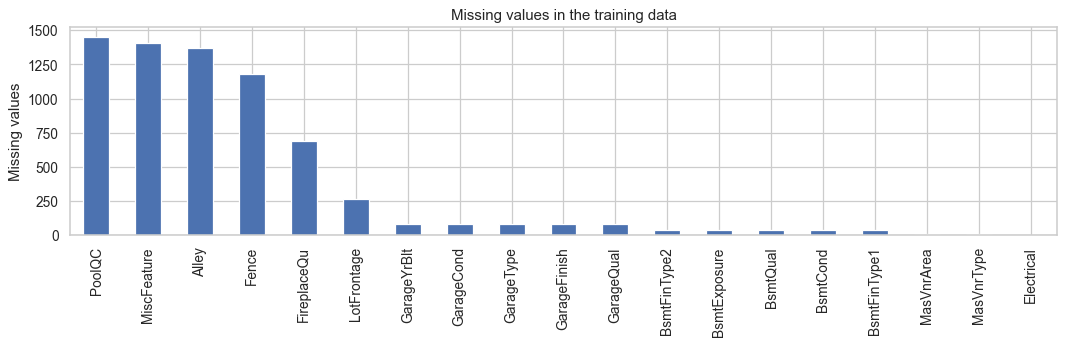

In [5]:
missing = train.isna().sum().sort_values(ascending=False)
print(missing[missing > 0])

missing[missing > 0].plot(kind="bar", figsize=(12, 4))
plt.ylabel("Missing values")
plt.title("Missing values in the training data")
plt.tight_layout()
plt.show()

### Area, quality and neighbourhood
Prices usually rise with living area and quality, but the two unusually large
houses labelled below do not follow that pattern. We retain houses 524 and
1299 and return to them when reviewing the remaining prediction errors.
Neighbourhood price distributions also differ, which gives us a reason to
consider local comparisons later.

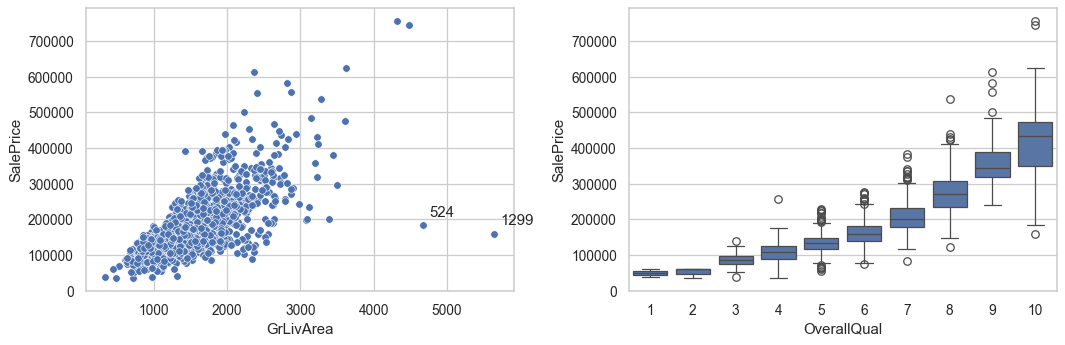

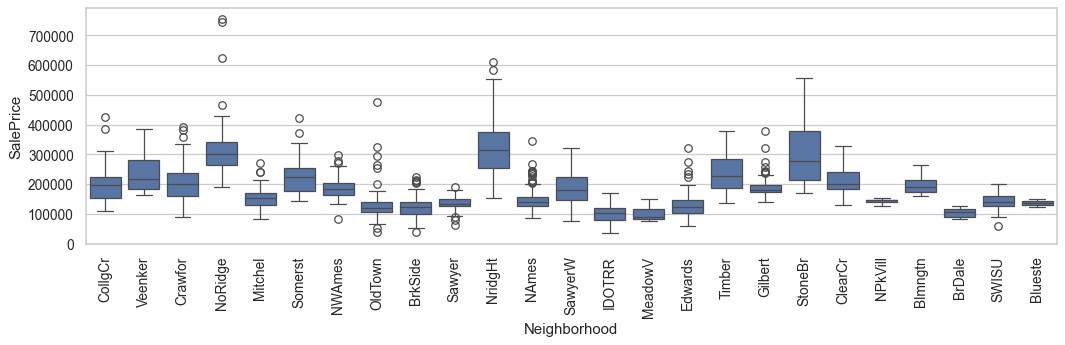

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", ax=axes[0])
for house_id in [524, 1299]:
    house = train.loc[train["Id"].eq(house_id)].iloc[0]
    axes[0].annotate(str(house_id), (house["GrLivArea"], house["SalePrice"]),
                     xytext=(5, 7), textcoords="offset points")
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=axes[1])
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
sns.boxplot(data=train, x="Neighborhood", y="SalePrice")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Checking related measurements
We compare the numerical measurements with each other and with `SalePrice`.
Several area and facility measurements overlap, so adding a new total may
repeat information already present. We test that possibility with a fixed
Ridge reference. `Id` and numerical category codes are excluded from this plot.

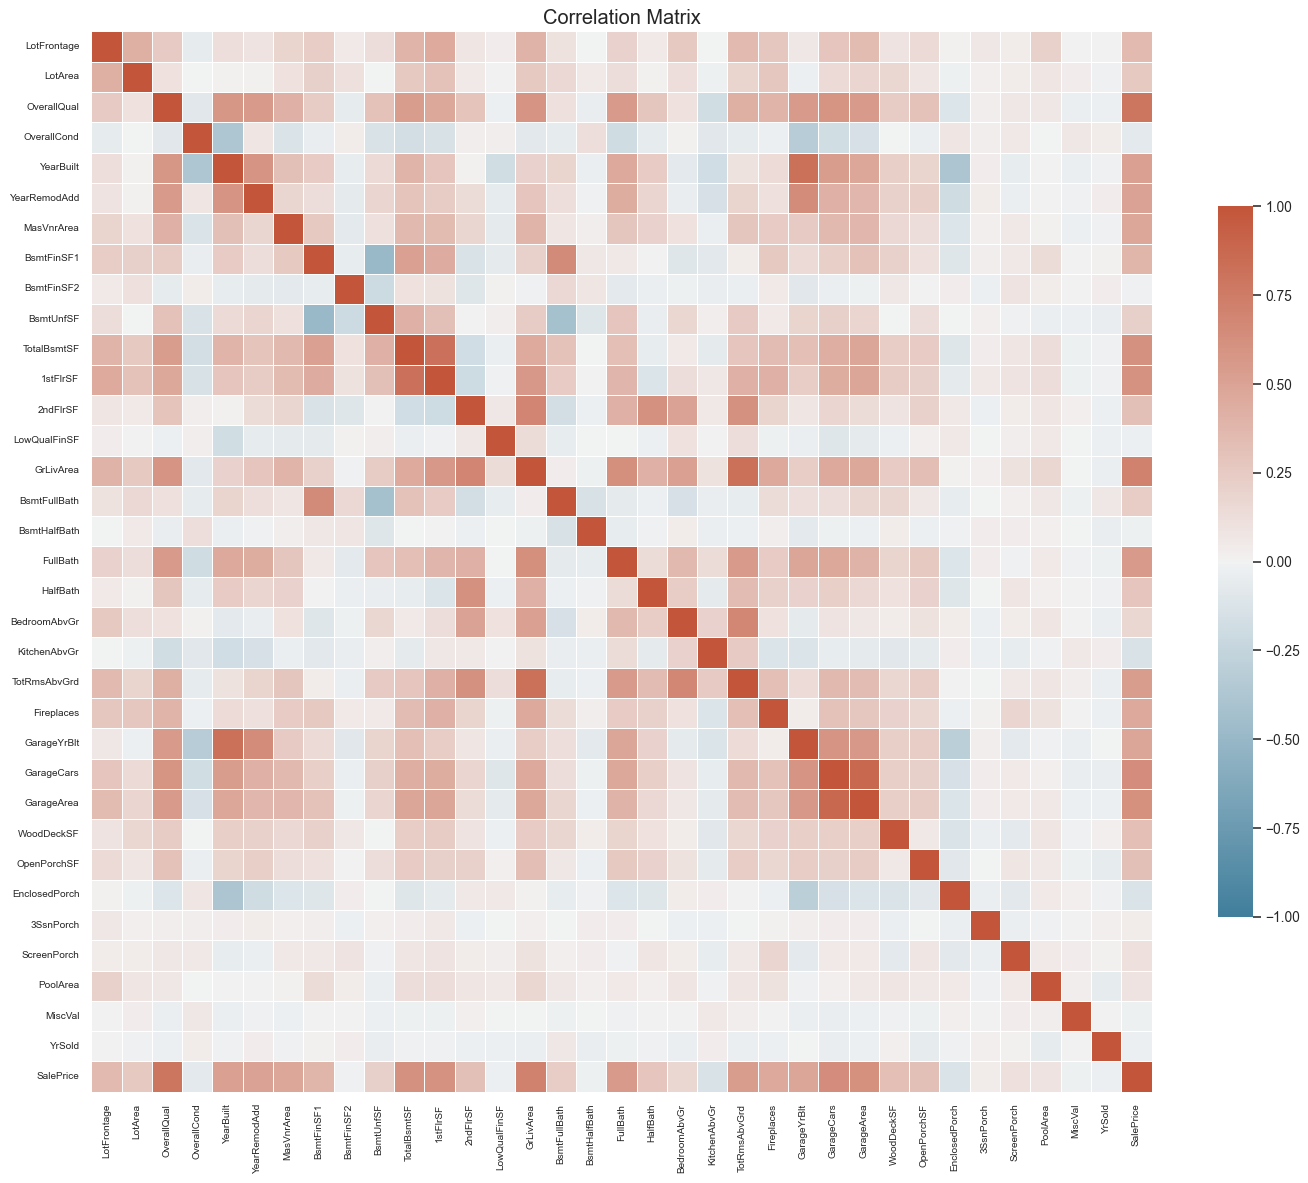

In [7]:
corr = train.drop(columns=["Id", "MSSubClass", "MoSold"]).select_dtypes(include=np.number).corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr, cmap=sns.diverging_palette(230, 20, as_cmap=True),
            center=0, vmin=-1, vmax=1, square=True, annot=False,
            linewidths=0.5, cbar_kws={"shrink": 0.6})
plt.title("Correlation Matrix", fontsize=16)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

<a id="v1-start"></a>
## V1: finding a useful starting point
### Simple cleaning rules
We wanted a reference that was quick to run and easy to change. We join the
feature rows to apply fixed cleaning rules consistently. Medians, modes,
dummy columns and scaling are learned from the training split later.

In [8]:
y = np.log(train["SalePrice"])
test_ids = test["Id"].copy()

train_features = train.drop(columns=["Id", "SalePrice"])
test_features = test.drop(columns="Id")
data = pd.concat([train_features, test_features], ignore_index=True)

### Missing facilities and invalid years
Our first rules are deliberately simple: missing facility descriptions become
`None`, and missing facility amounts become zero. This can treat some
incomplete records as absence. The later model runs use more specific checks
based on related measurements; we keep the original reference here.

We keep missing masonry descriptions as `Unknown`, treat invalid years as
missing, and interpret `MSSubClass` and `MoSold` as category codes.

In [9]:
none_columns = ["Alley", "Fence", "MiscFeature", "PoolQC", "FireplaceQu",
                "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
for col in none_columns:
    data[col] = data[col].fillna("None")

data["MasVnrType"] = data["MasVnrType"].fillna("Unknown")

zero_columns = ["GarageArea", "GarageCars", "TotalBsmtSF", "BsmtFinSF1",
                "BsmtFinSF2", "BsmtUnfSF", "BsmtFullBath", "BsmtHalfBath"]
for col in zero_columns:
    data[col] = data[col].fillna(0)

for col in ["YearBuilt", "YearRemodAdd", "GarageYrBlt"]:
    invalid_year = (data[col] < 1800) | (data[col] > data["YrSold"] + 1)
    print(col, "invalid years:", invalid_year.sum())
    data.loc[invalid_year, col] = np.nan

data["MSSubClass"] = data["MSSubClass"].astype(str)
data["MoSold"] = data["MoSold"].astype(str)

# Save the original column names for a feature-engineering comparison.
base_columns = data.columns.tolist()

YearBuilt invalid years: 0
YearRemodAdd invalid years: 1
GarageYrBlt invalid years: 1


### Giving the model six direct descriptions
We add combined floor area, total bathrooms, age at sale, age since remodelling,
and garage/basement indicators. The raw information is spread across several
columns. We want to check whether giving Ridge these summaries helps, while
allowing for the possibility that they repeat what it already knows.

In [10]:
data["TotalSF"] = data["TotalBsmtSF"] + data["1stFlrSF"] + data["2ndFlrSF"]
data["TotalBath"] = (data["FullBath"] + 0.5 * data["HalfBath"]
                     + data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"])
# Clip small negative ages to zero for houses sold around their construction year.
data["HouseAge"] = (data["YrSold"] - data["YearBuilt"]).clip(lower=0)
data["RemodelAge"] = (data["YrSold"] - data["YearRemodAdd"]).clip(lower=0)
data["HasGarage"] = (data["GarageArea"] > 0).astype(int)
data["HasBasement"] = (data["TotalBsmtSF"] > 0).astype(int)

new_columns = ["TotalSF", "TotalBath", "HouseAge", "RemodelAge", "HasGarage", "HasBasement"]
data[new_columns].head()

,TotalSF,TotalBath,HouseAge,RemodelAge,HasGarage,HasBasement
0,2566.0,3.5,5.0,5.0,1,1
1,2524.0,2.5,31.0,31.0,1,1
2,2706.0,3.5,7.0,6.0,1,1
3,2473.0,2.0,91.0,36.0,1,1
4,3343.0,3.5,8.0,8.0,1,1


### Reducing the effect of large area values
We use `log1p` for selected area columns, including zero-valued facilities.
We calculate combined area before taking logs and apply the same treatment
in both feature comparisons.

In [11]:
log_columns = ["LotArea", "GrLivArea", "TotalBsmtSF", "1stFlrSF",
               "2ndFlrSF", "MasVnrArea", "TotalSF"]
for col in log_columns:
    data[col] = np.log1p(data[col])

### Keeping the first comparison fair
We use one fixed 80/20 split for both feature sets. Remaining medians and
modes come from the training houses. We also learn dummy columns there and
align the validation columns to them.

In [12]:
X = data.iloc[:len(train)].copy()
X_test = data.iloc[len(train):].copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

medians = X_train.median(numeric_only=True)
modes = X_train.select_dtypes(include="object").mode().iloc[0]
X_train = X_train.fillna(medians).fillna(modes)
X_valid = X_valid.fillna(medians).fillna(modes)

# Identify the baseline columns before encoding adds dummy columns.
X_train_base = pd.get_dummies(X_train[base_columns], dtype=int)
X_valid_base = pd.get_dummies(X_valid[base_columns], dtype=int)
X_valid_base = X_valid_base.reindex(columns=X_train_base.columns, fill_value=0)

X_train = pd.get_dummies(X_train, dtype=int)
X_valid = pd.get_dummies(X_valid, dtype=int)
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Remaining missing values:", X_train.isna().sum().sum(), X_valid.isna().sum().sum())

Training: (1168, 332)
Validation: (292, 332)
Remaining missing values: 0 0


### Scaling the inputs
We scale the encoded columns so that their units do not determine how strongly
the Ridge penalty affects them. Each scaler sees only the training split.

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

base_scaler = StandardScaler()
X_train_base_scaled = base_scaler.fit_transform(X_train_base)
X_valid_base_scaled = base_scaler.transform(X_valid_base)

### A small initial improvement
We keep Ridge and its settings fixed, then compare the two feature sets.
The report rounds the resulting errors to 0.1243 and 0.1238. A small gain on
one split leaves open whether the inputs or the learner need more attention.

In [14]:
def fit_ridge_reference(training_matrix, target, prediction_matrix):
    # Same Ridge objective as V1, with a tightly converged LSQR solver.
    assert np.isfinite(training_matrix).all()
    assert np.isfinite(prediction_matrix).all() and np.isfinite(target).all()
    model = Ridge(alpha=10, solver="lsqr", tol=1e-10, max_iter=10000)
    start = perf_counter()
    with threadpool_limits(limits=1):
        model.fit(training_matrix, target)
        # Equivalent to predict(); avoids local BLAS warning flags.
        prediction = (prediction_matrix * model.coef_).sum(axis=1) + model.intercept_
    assert model.n_iter_[0] < model.max_iter
    assert np.isfinite(model.coef_).all()
    assert np.isfinite(prediction).all()
    return model, prediction, perf_counter() - start

ridge_base, base_pred, base_time = fit_ridge_reference(
    X_train_base_scaled, y_train, X_valid_base_scaled)
ridge, ridge_pred, ridge_time = fit_ridge_reference(
    X_train_scaled, y_train, X_valid_scaled)
base_score = np.sqrt(mean_squared_error(y_valid, base_pred))
ridge_score = np.sqrt(mean_squared_error(y_valid, ridge_pred))
feature_comparison = pd.DataFrame({
    "Features": ["Original", "Original + 6 new features"],
    "Validation log-RMSE": [base_score, ridge_score],
    "Fit seconds": [base_time, ridge_time],
    "Feature count": [X_train_base.shape[1], X_train.shape[1]],
})
feature_comparison.to_csv(OUTPUT_DIR / "ridge_feature_comparison.csv", index=False)
display(feature_comparison)

,Features,Validation log-RMSE,Fit seconds,Feature count
0,Original,0.124284,0.031228,326
1,Original + 6 new features,0.123827,0.013528,332


### Checking the remaining errors
We retain the lower-error feature set and inspect its predictions and residuals.
This split is used for selection, so its score is not an independent final test.

Model: Ridge (alpha=10)
Selected features: Original + 6 new features


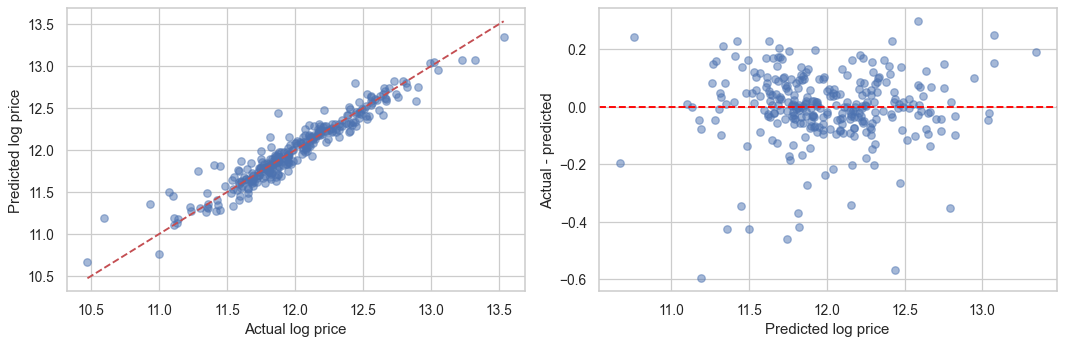

In [15]:
if ridge_score < base_score:
    selected_features = "Original + 6 new features"
    best_valid_pred = ridge_pred
else:
    selected_features = "Original"
    best_valid_pred = base_pred

print("Model: Ridge (alpha=10)")
print("Selected features:", selected_features)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_valid, best_valid_pred, alpha=0.5)
axes[0].plot([y_valid.min(), y_valid.max()], [y_valid.min(), y_valid.max()], "r--")
axes[0].set(xlabel="Actual log price", ylabel="Predicted log price")
axes[1].scatter(best_valid_pred, y_valid - best_valid_pred, alpha=0.5)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Predicted log price", ylabel="Actual - predicted")
plt.tight_layout()
plt.show()

### Refit the reference and save its predictions
We learn filling, dummy columns and scaling again from all labelled houses,
then fit Ridge for the test set. We save this reference separately from the
final combined submission.

In [16]:
medians = X.median(numeric_only=True)
modes = X.select_dtypes(include="object").mode().iloc[0]
X_full = X.fillna(medians).fillna(modes)
X_test_full = X_test.fillna(medians).fillna(modes)

if selected_features == "Original":
    X_full = X_full[base_columns]
    X_test_full = X_test_full[base_columns]

X_full = pd.get_dummies(X_full, dtype=int)
X_test_full = pd.get_dummies(X_test_full, dtype=int)
X_test_full = X_test_full.reindex(columns=X_full.columns, fill_value=0)

scaler = StandardScaler()
X_full_scaled = scaler.fit_transform(X_full)
X_test_scaled = scaler.transform(X_test_full)

final_ridge, test_pred_log, full_fit_seconds = fit_ridge_reference(
    X_full_scaled, y, X_test_scaled
)

In [17]:
ridge_submission = pd.DataFrame({"Id": test_ids, "SalePrice": np.exp(test_pred_log)})
assert len(ridge_submission) == len(test) and ridge_submission["Id"].equals(test["Id"])
assert np.isfinite(ridge_submission["SalePrice"]).all()
assert ridge_submission["SalePrice"].gt(0).all()
ridge_path = OUTPUT_DIR / "submission_ridge_baseline.csv"
ridge_submission.to_csv(ridge_path, index=False)
print("Selected features:", selected_features)
print(f"Holdout log-RMSE: {min(base_score, ridge_score):.6f}")
print("Baseline saved:", ridge_path.relative_to(REPO_ROOT))
display(ridge_submission.head().round(2))

Selected features: Original + 6 new features
Holdout log-RMSE: 0.123827
Baseline saved: final_outputs/submission_ridge_baseline.csv


,Id,SalePrice
0,1461,120785.20
1,1462,174191.86
2,1463,185991.38
3,1464,204877.29
4,1465,196631.13


<a id="v2-comparison"></a>
## V2: comparing and combining predictions
The six features gave us only a small gain. We wondered whether a different
learner could use combinations of size, quality and age more effectively.
We therefore compared Ridge and Gradient Boosting on five shuffled folds
with seed 42, then tried an equal average of their log predictions.

Here we recalculate the errors from the saved OOF predictions. These are the
recorded development runs discussed in the report. V1's single-split error
and these five-fold errors use different evaluation settings.

In [18]:
v2_oof = pd.read_csv(asset_path("experiment_records", "v2_oof"))
assert v2_oof["Id"].equals(train["Id"])
true_log = np.log(train["SalePrice"].to_numpy())
np.testing.assert_allclose(v2_oof["Actual price"], train["SalePrice"])
ridge_oof = v2_oof["Ridge log prediction"].to_numpy()
gbr_oof = v2_oof["GBR log prediction"].to_numpy()
equal_blend_oof = 0.5 * ridge_oof + 0.5 * gbr_oof
np.testing.assert_allclose(np.exp(equal_blend_oof), v2_oof["Blend predicted price"])

def log_rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2)))

v2_comparison = pd.DataFrame({
    "Model": ["Ridge", "Gradient Boosting", "Equal log-price blend"],
    "Recorded OOF log-RMSE": [log_rmse(true_log, prediction)
                              for prediction in [ridge_oof, gbr_oof, equal_blend_oof]],
})
display(v2_comparison)
v2_folds = pd.read_csv(asset_path("experiment_records", "v2_folds"))
display(v2_folds[["Fold", "Ridge", "Gradient Boosting", "Equal blend"]])
print("Blend improves on Ridge in all five saved folds:",
      bool(v2_folds["Equal blend"].lt(v2_folds["Ridge"]).all()))
residual_correlation = np.corrcoef(true_log - ridge_oof, true_log - gbr_oof)[0, 1]
print(f"Recorded residual correlation: {residual_correlation:.3f}")

,Model,Recorded OOF log-RMSE
0,Ridge,0.140043
1,Gradient Boosting,0.133172
2,Equal log-price blend,0.127864


,Fold,Ridge,Gradient Boosting,Equal blend
0,1,0.123827,0.132532,0.120870
1,2,0.120620,0.118423,0.111238
2,3,0.189612,0.163404,0.169639
3,4,0.138173,0.127003,0.120021
4,5,0.114603,0.119390,0.107611


Blend improves on Ridge in all five saved folds: True
Recorded residual correlation: 0.752


The equal blend lowered the OOF error to about 0.1279, below either learner
alone. Ridge was weaker overall but still contributed useful differences in
its errors. We kept the combination and revisited the houses it overestimated.

<a id="v3-inputs"></a>
## V3: improving the inputs and comparing alternatives
We were still overestimating some unusually large houses. In the later runs,
we refined the facility checks, used training-fold neighbourhood medians for
frontage, and added finished area, outdoor area, garage age and a few quality
interactions. Ordered quality descriptions, rare categories and skewed
measurements also received more specific treatment.

We paid particular attention to scale when trying SVR. The comparison below
keeps its parameters fixed and changes only the cap on continuous inputs.
These are saved experiment results; no houses or true prices were removed.

,Input treatment,Recorded OOF log-RMSE
0,No cap,0.126337
1,99% cap,0.121497
2,98% cap,0.122442


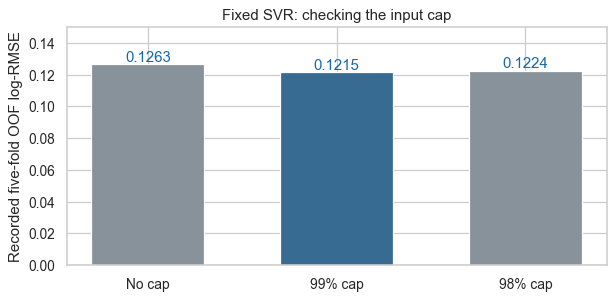

In [19]:
candidates = pd.read_csv(asset_path("experiment_records", "v3_candidates")).set_index("model")
specifications = json.loads(asset_path("experiment_records", "v3_specs").read_text())
cap_trials = ["svr_fine_c10_g0.0001", "svr_advanced_clip99_c10_g0.0001",
              "svr_advanced_clip98_c10_g0.0001"]
for name in cap_trials[1:]:
    assert specifications[name]["params"] == specifications[cap_trials[0]]["params"]
cap_comparison = pd.DataFrame({
    "Input treatment": ["No cap", "99% cap", "98% cap"],
    "Recorded OOF log-RMSE": candidates.loc[cap_trials, "oof_log_rmse"].to_numpy(),
})
display(cap_comparison)
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(cap_comparison["Input treatment"], cap_comparison["Recorded OOF log-RMSE"],
              color=["#88929B", "#386B92", "#88929B"], width=0.6)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002,
            f"{bar.get_height():.4f}", ha="center", color="#1769AA")
ax.set(ylim=(0, 0.15), ylabel="Recorded five-fold OOF log-RMSE", title="Fixed SVR: checking the input cap")
plt.tight_layout()
plt.show()

### Changes that did not work as we expected
The 99% cap helped SVR; the stronger 98% cap lost part of that gain. We also
checked whether a different scaler or the same cap helped other learners.
The comparisons below kept model parameters fixed within each pair.

In [20]:
trial_pairs = [
    ("SVR: standard to robust scaling", "svr_v2_c20_g0.0003", "svr_v2_robust_g0.0003"),
    ("XGBoost: no cap to 99% cap", "xgb_d3_n2000", "xgb_clip99"),
    ("Ridge: remove to keep quality interactions", "ridge_reduced_10", "ridge_a10"),
]
failed_or_small = []
for treatment, reference, alternative in trial_pairs:
    assert specifications[reference]["params"] == specifications[alternative]["params"]
    failed_or_small.append({
        "Treatment checked": treatment,
        "Reference OOF log-RMSE": candidates.loc[reference, "oof_log_rmse"],
        "Alternative OOF log-RMSE": candidates.loc[alternative, "oof_log_rmse"],
    })
display(pd.DataFrame(failed_or_small))
v3_oof = pd.read_csv(asset_path("experiment_records", "v3_oof"))
assert v3_oof["Id"].equals(train["Id"])
np.testing.assert_allclose(v3_oof["true_log_price"], true_log, atol=1e-12)
display(pd.read_csv(asset_path("experiment_records", "v3_model_comparison")))
print(f"Recalculated recorded V3 blend OOF log-RMSE: {log_rmse(true_log, v3_oof['v3_oof_log']):.6f}")

,Treatment checked,Reference OOF log-RMSE,Alternative OOF log-RMSE
0,SVR: standard to robust scaling,0.134229,0.186804
1,XGBoost: no cap to 99% cap,0.126523,0.126695
2,Ridge: remove to keep quality interactions,0.138183,0.138096


,Model,OOF log-RMSE,Fold mean,Fold standard deviation
0,V3 blend,0.117973,0.117102,0.016002
1,svr,0.121497,0.120911,0.013327
2,cat,0.123452,0.122471,0.017360
3,xgb,0.126523,0.125117,0.021032


Recalculated recorded V3 blend OOF log-RMSE: 0.117973


Robust scaling hurt this SVR setting, and the cap did not help XGBoost.
The quality interactions gave only a small gain. These checks led us to keep
processing choices specific to each learner. We retained a small SVR,
XGBoost and CatBoost blend, then returned to the unusually large houses.

<a id="v4-neighbourhood"></a>
## V4: putting each house in its neighbourhood
We wondered whether a house's area meant the same thing in every neighbourhood.
The later recipe used training-fold neighbourhood medians to express relative
size and quality, together with a few interactions. We also tried neighbourhood
price summaries: each training row's own target was excluded, and validation
houses used only training-fold tables.

We kept a context SVR, CatBoost, ElasticNet and a complementary SVR branch.
Several choices changed together, so we judged the complete recipe against a
fresh reproduction of V3. The tables below are copied from the executed
neighbourhood notebook at its displayed six-decimal precision. They record the
paired checks on two splits; this cell does not refit those models.

In [21]:
neighbourhood_review = assets["neighbourhood_review"]
paired_checks = pd.DataFrame(neighbourhood_review["paired_scores"]).set_index("Seed")
display(paired_checks)
fold_checks = pd.DataFrame(neighbourhood_review["fold_scores"])
assert fold_checks["Rows"].eq(292).all()
fold_pairs = fold_checks.pivot(index=["Seed", "Fold"], columns="Model", values="log-RMSE")
improved_folds = int(fold_pairs["V4"].lt(fold_pairs["V3"]).sum())
print(f"V4 improves {improved_folds} of {len(fold_pairs)} recorded fold comparisons.")
assert improved_folds == 9 and paired_checks["V4"].lt(paired_checks["V3 reproduced"]).all()

,V3 reproduced,V4
Seed,,
42,0.117905,0.114679
2026,0.115709,0.113709


V4 improves 9 of 10 recorded fold comparisons.


Both splits favoured the revised recipe. That supported keeping neighbourhood
context and the combination together, without attributing the whole gain to
one feature. We then focused on the final predictions and on sale conditions
that might make a house unlike an ordinary transaction.

<a id="v5-final"></a>
## V5: refining the final predictions
### Combining predictions by sale condition
Different predictors had already helped correct one another's errors. We
continued with earlier stacking and SVR/CatBoost work, then added TabICLv2 and
Kumo predictions for normal sales while keeping the preceding blend elsewhere.
All of the following operations belong to this final milestone.

We use saved component predictions here and check every intermediate result
against its recorded file. The transformations, tail treatment and weights
are fixed. The Ridge holdout results above do not tune this final recipe.

In [22]:
def read_component(name, expected_ids):
    specification = assets["components"][name]
    frame = pd.read_csv(asset_path("components", name))
    if not frame["Id"].equals(expected_ids):
        raise ValueError(f"{name} has different house IDs or row order")
    values = frame[specification["column"]].to_numpy()
    if not np.isfinite(values).all() or not (values > 0).all():
        raise ValueError(f"{name} has invalid predictions")
    return values

def encode_prices(ids, prices):
    return pd.DataFrame({"Id": ids, "SalePrice": prices}).to_csv(index=False).encode("utf-8")

def read_prices(payload):
    return pd.read_csv(BytesIO(payload))["SalePrice"].to_numpy()

def combine_stacking_and_svm(ids):
    stack = read_component("stacking", ids)
    svm = read_component("svm", ids)
    # Preserve the transformation used in the recorded component combination.
    raw = np.expm1(np.sqrt(stack * np.log(svm)))
    low, high = np.quantile(raw, [0.0042, 0.99])
    adjusted = raw.copy()
    adjusted[raw <= low] *= 0.77
    adjusted[raw >= high] *= 1.10
    return encode_prices(ids, adjusted)

def add_svr_catboost_predictions(ids, stacking_payload):
    correction = read_component("svr_catboost", ids)
    prices = np.exp(0.5 * np.log(read_prices(stacking_payload)) + 0.5 * np.log(correction))
    return encode_prices(ids, prices)

def blend_by_sale_condition(test, preceding_payload):
    ids = test["Id"]
    normal = test["SaleCondition"].eq("Normal").to_numpy()
    tabicl = read_component("tabicl", ids)
    kumo = read_component("kumo", ids)
    prices = read_prices(preceding_payload).copy()
    intermediate = prices.copy()
    intermediate[normal] = np.exp(0.75 * np.log(prices[normal]) + 0.25 * tabicl[normal])
    # Preserve the saved-and-reloaded intermediate used in the recorded run.
    intermediate = read_prices(encode_prices(ids, intermediate))
    prices[normal] = np.exp(0.25 * np.log(intermediate[normal]) + 0.75 * kumo[normal])
    return encode_prices(ids, prices)

def large_partial_new_sales(frame):
    age = frame["YrSold"] - frame["YearBuilt"]
    return (frame["SaleCondition"].eq("Partial") & frame["SaleType"].eq("New")
            & frame["GrLivArea"].gt(4000) & age.between(-1, 1))

def adjust_with_comparable_sales(train, test, preceding_payload):
    candidates = train.loc[large_partial_new_sales(train)]
    base = read_prices(preceding_payload)
    prices_by_id = {}
    for i in np.flatnonzero(large_partial_new_sales(test).to_numpy()):
        row = test.iloc[i]
        similar = candidates[
            candidates["Neighborhood"].eq(row["Neighborhood"])
            & candidates["BldgType"].eq(row["BldgType"])
            & candidates["OverallQual"].sub(row["OverallQual"]).abs().le(1)
            & np.log(candidates["GrLivArea"] / row["GrLivArea"]).abs().le(0.25)
            & np.log(candidates["LotArea"] / row["LotArea"]).abs().le(0.60)]
        if similar.empty:
            continue
        reference = np.median(np.log(similar["SalePrice"].to_numpy()))
        estimate = np.exp(0.5 * np.log(base[i]) + 0.5 * reference)
        prices_by_id[str(row["Id"])] = f"{estimate:.8f}"
    output = StringIO()
    writer = csv.DictWriter(output, fieldnames=["Id", "SalePrice"], lineterminator="\n")
    writer.writeheader()
    for row in csv.DictReader(StringIO(preceding_payload.decode("utf-8"))):
        row["SalePrice"] = prices_by_id.get(row["Id"], row["SalePrice"])
        writer.writerow(row)
    return output.getvalue().encode("utf-8")

In [23]:
verification_rows = []
def check_recorded_prediction(checkpoint, payload):
    expected_path = asset_path("checkpoints", checkpoint)
    expected = pd.read_csv(expected_path)
    actual = pd.read_csv(BytesIO(payload))
    assert actual.columns.tolist() == ["Id", "SalePrice"]
    assert actual["Id"].equals(test["Id"]) and expected["Id"].equals(test["Id"])
    assert actual["Id"].is_unique and len(actual) == len(test)
    assert np.isfinite(actual["SalePrice"]).all() and actual["SalePrice"].gt(0).all()
    np.testing.assert_allclose(actual["SalePrice"], expected["SalePrice"], rtol=1e-12, atol=1e-7,
                               err_msg=f"{checkpoint} differs from its recorded predictions")
    verification_rows.append({
        "Final-stage operation": checkpoint.replace("_", " "), "Rows": len(actual),
        "Maximum price difference": float(np.max(np.abs(actual["SalePrice"] - expected["SalePrice"]))),
        "Numerically matched": True, "Byte-identical": payload == expected_path.read_bytes(),
    })
    return actual

### Build the preceding combination
We retain the earlier stacking/SVM combination, including its fixed tail
treatment, then give equal weight to it and the SVR/CatBoost pipeline on the
log-price scale. These are components of the final recipe.

In [24]:
stacking_payload = combine_stacking_and_svm(test["Id"])
stacking_prices = check_recorded_prediction("stacking_svm", stacking_payload)
corrected_payload = add_svr_catboost_predictions(test["Id"], stacking_payload)
corrected_prices = check_recorded_prediction("corrected_blend", corrected_payload)
display(corrected_prices.head().round(2))

,Id,SalePrice
0,1461,121755.31
1,1462,163700.14
2,1463,185220.03
3,1464,197044.14
4,1465,189088.16


### Add further predictions for normal sales
An ordinary sale and a less typical transaction might not follow the same
price relationships. We use the expanded combination for normal sales and
retain the preceding predictions for other conditions. Its effective log-price
weights are 18.75% preceding blend, 6.25% TabICLv2 and 75% Kumo.

In [25]:
sale_blend_payload = blend_by_sale_condition(test, corrected_payload)
sale_blend_prices = check_recorded_prediction("sale_condition_blend", sale_blend_payload)
normal_sales = test["SaleCondition"].eq("Normal")
np.testing.assert_allclose(sale_blend_prices.loc[~normal_sales, "SalePrice"],
                           corrected_prices.loc[~normal_sales, "SalePrice"], rtol=1e-12, atol=1e-7)
display(pd.DataFrame({"Sale group": ["Normal", "Other conditions"],
                      "Houses": [int(normal_sales.sum()), int((~normal_sales).sum())],
                      "Prediction": ["Expanded blend", "Preceding blend"]}))

,Sale group,Houses,Prediction
0,Normal,1204,Expanded blend
1,Other conditions,255,Preceding blend


### Returning to the unusual large houses
We check the estimate for a similar test house against actual training sales.
We restrict the check to new houses above 4,000 square feet, marked `Partial`,
with a sale/construction-year difference between -1 and 1. `Partial` means
incomplete when last assessed; it does not automatically imply a low price.

Comparables must share neighbourhood and building type, differ by at most one
quality grade, and meet the fixed limits on log living-area and lot-area
ratios (0.25 and 0.60). We combine the preceding log estimate equally with
the median log price of the matched training sales.

In [26]:
final_payload = adjust_with_comparable_sales(train, test, sale_blend_payload)
final_submission = check_recorded_prediction("final", final_payload)
case_comparison = pd.DataFrame({
    "Id": test["Id"], "Before comparable adjustment": sale_blend_prices["SalePrice"],
    "Final V5 price": final_submission["SalePrice"],
})
changed = ~np.isclose(
    case_comparison["Before comparable adjustment"], case_comparison["Final V5 price"],
    rtol=1e-12, atol=1e-7)
print("Houses changed by the final rule:", int(changed.sum()))
display(case_comparison.loc[changed].round(2))
candidate_sales = train.loc[large_partial_new_sales(train)]
comparable_records = []
for i in np.flatnonzero(changed):
    house = test.iloc[i]
    similar = candidate_sales[
        candidate_sales["Neighborhood"].eq(house["Neighborhood"])
        & candidate_sales["BldgType"].eq(house["BldgType"])
        & candidate_sales["OverallQual"].sub(house["OverallQual"]).abs().le(1)
        & np.log(candidate_sales["GrLivArea"] / house["GrLivArea"]).abs().le(0.25)
        & np.log(candidate_sales["LotArea"] / house["LotArea"]).abs().le(0.60)]
    for _, row in similar.iterrows():
        comparable_records.append({
            "Test Id": int(house["Id"]), "Comparable train Id": int(row["Id"]),
            "Living area": row["GrLivArea"], "Lot area": row["LotArea"],
            "Quality": row["OverallQual"], "Known training price": row["SalePrice"],
        })
comparable_audit = pd.DataFrame(comparable_records)
display(comparable_audit)
assert int(changed.sum()) == 1
assert case_comparison.loc[changed, "Id"].tolist() == [2550]
assert sorted(comparable_audit["Comparable train Id"].tolist()) == [524, 1299]

Houses changed by the final rule: 1


,Id,Before comparable adjustment,Final V5 price
1089,2550,339331.06,241539.36


,Test Id,Comparable train Id,Living area,Lot area,Quality,Known training price
0,2550,524,4676,40094,10,184750
1,2550,1299,5642,63887,10,160000


The rule matches test house 2550 to training houses 524 and 1299, which we
identified in the EDA. Its estimate falls from about $339,000 to $242,000;
the other 1,458 predictions stay unchanged. The recorded submission improved,
but one matched test case gives us limited evidence for applying this rule broadly.

<a id="submission-results"></a>
## Submission results and final checks
### Largest submission improvement
During V5, adding TabICLv2 and Kumo for normal sales gave our largest recorded
improvement between consecutive submissions: 0.11419 to 0.11194. The final
comparable-sale adjustment then lowered the recorded score to 0.11101.
These are Kaggle results from the report, not scores measured by this local run.

In [27]:
submission_results = pd.DataFrame({
    "Milestone": ["V3", "V4", "V5"],
    "Recorded Kaggle log-RMSE": [0.11881, 0.11735, 0.11101],
})
display(submission_results)
final_steps = pd.DataFrame({
    "Within V5": ["Preceding blend", "Normal-sale combination", "Final comparable-sale adjustment"],
    "Recorded Kaggle log-RMSE": [0.11419, 0.11194, 0.11101],
})
final_steps["Decrease from preceding submission"] = -final_steps["Recorded Kaggle log-RMSE"].diff()
display(final_steps)

,Milestone,Recorded Kaggle log-RMSE
0,V3,0.11881
1,V4,0.11735
2,V5,0.11101


,Within V5,Recorded Kaggle log-RMSE,Decrease from preceding submission
0,Preceding blend,0.11419,NaN
1,Normal-sale combination,0.11194,0.00225
2,Final comparable-sale adjustment,0.11101,0.00093


### Verify and export
We check row order, positive finite predictions and the recorded intermediate
results before writing the final submission. Tiny floating-point differences
are allowed when checking numerical agreement across environments.

In [28]:
assert frame_fingerprint(train) == raw_fingerprints["train"]
assert frame_fingerprint(test) == raw_fingerprints["test"]
assert len(final_submission) == 1459 and final_submission["Id"].is_unique
assert final_submission["SalePrice"].notna().all()
assert np.isfinite(final_submission["SalePrice"]).all()
assert final_submission["SalePrice"].gt(0).all()
final_path = OUTPUT_DIR / "submission_final.csv"
final_path.write_bytes(final_payload)
verification = pd.DataFrame(verification_rows)
verification.to_csv(OUTPUT_DIR / "final_prediction_checks.csv", index=False)
case_comparison.loc[changed].to_csv(OUTPUT_DIR / "comparable_adjustments.csv", index=False)
comparable_audit.to_csv(OUTPUT_DIR / "comparable_training_sales.csv", index=False)
display(verification)
print("Final submission:", final_path.relative_to(REPO_ROOT))
print("Recorded final V5 Kaggle log-RMSE: 0.11101")
display(final_submission.head().round(2))

,Final-stage operation,Rows,Maximum price difference,Numerically matched,Byte-identical
0,stacking svm,1459,9.313226e-10,True,False
1,corrected blend,1459,8.731149e-10,True,False
2,sale condition blend,1459,1.862645e-09,True,False
3,final,1459,1.862645e-09,True,False


Final submission: final_outputs/submission_final.csv
Recorded final V5 Kaggle log-RMSE: 0.11101


,Id,SalePrice
0,1461,122413.87
1,1462,161599.65
2,1463,187559.05
3,1464,198818.62
4,1465,182330.24


### Save the run record
We record the source snapshot, software versions and input hashes. The run
record distinguishes the Ridge training from the saved experiment reviews
and the final component combination.

In [29]:
run_record = {
    "source_commit": SOURCE_COMMIT, "python": platform.python_version(),
    "packages": {name: importlib.metadata.version(name)
                 for name in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn"]},
    "report_milestones": ["V1", "V2", "V3", "V4", "V5"],
    "training_rows": len(train), "test_rows": len(test),
    "ridge_selected_features": selected_features,
    "ridge_holdout_log_rmse": float(min(base_score, ridge_score)),
    "recorded_final_kaggle_log_rmse": 0.11101,
    "later_comparison_source": "Saved development predictions and experiment records",
    "final_component_retraining": False,
    "changed_test_houses": int(changed.sum()),
    "all_recorded_checkpoints_matched": bool(verification["Numerically matched"].all()),
    "asset_manifest_sha256": sha256(ASSET_MANIFEST.read_bytes()).hexdigest(),
    "input_sha256": {f"{section}/{name}": specification["sha256"]
                     for section in ["components", "checkpoints", "experiment_records"]
                     for name, specification in assets[section].items()},
    "dataset_sha256": {name: sha256((DATA_DIR / name).read_bytes()).hexdigest()
                       for name in ["train.csv", "test.csv"]},
    "final_submission_sha256": sha256(final_payload).hexdigest(),
}
(OUTPUT_DIR / "run_manifest_final.json").write_text(json.dumps(run_record, indent=2) + "\n", encoding="utf-8")
v2_comparison.to_csv(OUTPUT_DIR / "model_review_v2.csv", index=False)
cap_comparison.to_csv(OUTPUT_DIR / "input_cap_review.csv", index=False)
paired_checks.to_csv(OUTPUT_DIR / "neighbourhood_review.csv")
submission_results.to_csv(OUTPUT_DIR / "submission_milestones.csv", index=False)
print("Saved run_manifest_final.json and the review tables.")

Saved run_manifest_final.json and the review tables.


## Source records and technical references
- [Competition and evaluation](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview/evaluation)
- [Starting-point notebook](house_prices_v1.ipynb) and [five-fold comparison](house_prices_v2.ipynb)
- [Input/model comparisons](house_prices_v3.ipynb) and [neighbourhood recipe](house_prices_v4.ipynb)
- [Experiment records](v3_experiments/) and [asset manifest](final_versions/notebook_assets.json)
- [scikit-learn Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)

The asset manifest preserves the original archive paths and hashes. The notebook
uses the same five milestone names as the project report.